# 01 · Exploración de los datos — Desempeño de las ventas

**Reto 1:** analizar el desempeño de las ventas y del personal de ventas (generación, tendencia, contribución y perfil para contratación).

Este notebook corresponde a la fase de **comprensión de los datos** de CRISP-DM. Aquí se revisa la calidad de las siete tablas, se toman las decisiones de limpieza y se buscan los patrones que guían el modelado. Las decisiones que salen de aquí se implementan en los pipelines de Kedro (`data_processing`, `feature_engineering` y `sales_analysis`), que son los que producen los resultados finales.

Los datos se leen desde el **catálogo de Kedro** (`conf/base/catalog.yml`), con las mismas rutas y opciones de lectura que los pipelines.

> Para ejecutarlo: copiar los CSV del curso en `data/01_raw/` y abrir el notebook con el kernel del entorno del proyecto.

**Contenido**
1. Carga de las tablas y validación de llaves
2. Faltantes, duplicados y columnas a recalcular
3. Distribuciones y outliers
4. Patrones de venta, vendedores y señal para el modelo
5. Conclusiones y decisiones de limpieza

## 1. Carga de las tablas y validación de llaves

Diagrama entidad-relación del dataset:

![ERD](../docs/erd.png)

In [1]:
import os
from pathlib import Path

import pandas as pd
from kedro.config import OmegaConfigLoader
from kedro.io import DataCatalog

# las rutas del catálogo son relativas a la raíz del proyecto
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT)

# catálogo del proyecto (mismas rutas y opciones de lectura que los pipelines)
config = OmegaConfigLoader(
    str(PROJECT / "conf"), base_env="base", default_run_env="local"
)
catalog = DataCatalog.from_config(config["catalog"])

pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
names = [
    "sales",
    "products",
    "categories",
    "employees",
    "customers",
    "cities",
    "countries",
]
raw = {name: catalog.load(f"raw_{name}") for name in names}

pd.DataFrame(
    {
        "filas": {n: len(df) for n, df in raw.items()},
        "columnas": {n: df.shape[1] for n, df in raw.items()},
        "memoria (MB)": {
            n: df.memory_usage(deep=True).sum() / 1e6 for n, df in raw.items()
        },
    }
)

,filas,columnas,memoria (MB)
sales,6758125,9,776.48
products,452,9,0.06
categories,11,2,0.00
employees,23,8,0.00
customers,98759,6,7.92
cities,96,4,0.00
countries,206,3,0.01


`sales` es la tabla de hechos: cada fila es una línea de venta, con el vendedor (`SalesPersonID`), el cliente, el producto, la cantidad, el descuento y la fecha. Las demás tablas son dimensiones. Para el Reto 1 las más importantes son **`employees`** (perfil del vendedor) y **`products`** (precio para calcular el ingreso).

In [3]:
sales = raw["sales"]
sales.head()

,SalesID,SalesPersonID,CustomerID,ProductID,Quantity,Discount,TotalPrice,SalesDate,TransactionNumber
0,1,6,27039,381,7,0.00,0.00,2018-02-05 07:38:25.430,FQL4S94E4ME1EZFTG42G
1,2,16,25011,61,7,0.00,0.00,2018-02-02 16:03:31.150,12UGLX40DJ1A5DTFBHB8
2,3,13,94024,23,24,0.00,0.00,2018-05-03 19:31:56.880,5DT8RCPL87KI5EORO7B0
3,4,8,73966,176,19,0.20,0.00,2018-04-07 14:43:55.420,R3DR9MLD5NR76VO17ULE
4,5,10,32653,310,9,0.00,0.00,2018-02-12 15:37:03.940,4BGS0Z5OMAZ8NDAFHHP3


In [4]:
sales.dtypes.to_frame("tipo").T

,SalesID,SalesPersonID,CustomerID,ProductID,Quantity,Discount,TotalPrice,SalesDate,TransactionNumber
tipo,int64,int64,int64,int64,int64,float64,float64,str,str


`SalesDate` viene como texto, así que hay que convertirla a fecha. Ahora se valida que cada llave foránea tenga correspondencia en su tabla de origen: una venta con un producto, cliente o vendedor inexistente no podría analizarse.

In [5]:
def orphans(child, child_key, parent, parent_key):
    # filas de child cuya llave no existe en parent
    return int((~child[child_key].isin(parent[parent_key])).sum())


checks = [
    ("sales.ProductID → products", sales, "ProductID", raw["products"], "ProductID"),
    (
        "sales.CustomerID → customers",
        sales,
        "CustomerID",
        raw["customers"],
        "CustomerID",
    ),
    (
        "sales.SalesPersonID → employees",
        sales,
        "SalesPersonID",
        raw["employees"],
        "EmployeeID",
    ),
    (
        "products.CategoryID → categories",
        raw["products"],
        "CategoryID",
        raw["categories"],
        "CategoryID",
    ),
    ("customers.CityID → cities", raw["customers"], "CityID", raw["cities"], "CityID"),
    ("employees.CityID → cities", raw["employees"], "CityID", raw["cities"], "CityID"),
    (
        "cities.CountryID → countries",
        raw["cities"],
        "CountryID",
        raw["countries"],
        "CountryID",
    ),
]
pd.DataFrame(
    [(name, orphans(c, ck, p, pk)) for name, c, ck, p, pk in checks],
    columns=["relación", "llaves huérfanas"],
)

,relación,llaves huérfanas
0,sales.ProductID → products,0
1,sales.CustomerID → customers,0
2,sales.SalesPersonID → employees,0
3,products.CategoryID → categories,0
4,customers.CityID → cities,0
5,employees.CityID → cities,0
6,cities.CountryID → countries,0


In [6]:
print(
    "Vendedores en ventas:",
    sales["SalesPersonID"].nunique(),
    "de",
    len(raw["employees"]),
)
print("Productos vendidos:", sales["ProductID"].nunique(), "de", len(raw["products"]))
print(
    "Clientes con compras:", sales["CustomerID"].nunique(), "de", len(raw["customers"])
)
print("Países con ciudades:", raw["cities"]["CountryID"].unique())

Vendedores en ventas: 23 de 23
Productos vendidos: 452 de 452
Clientes con compras: 98759 de 98759
Países con ciudades: [32]


**Hallazgos de la sección 1**

- Las relaciones están **completas**: no hay llaves huérfanas en ninguna tabla. Los 23 vendedores, los 452 productos y los 98,759 clientes aparecen en las ventas.
- Todas las ciudades pertenecen a **un solo país** (`CountryID` 32), así que un análisis por país no aporta. La dimensión geográfica útil es la ciudad.
- `SalesDate` hay que convertirla a fecha.
- **Decisión:** la validación de llaves se repite en cada ejecución del pipeline (`data_processing.build_sales_primary`), que se detiene con error si aparece una llave huérfana en datos futuros.

## 2. Faltantes, duplicados y columnas a recalcular

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

missing = pd.concat(
    {
        name: pd.DataFrame(
            {"faltantes": df.isna().sum(), "% faltantes": 100 * df.isna().mean()}
        )
        for name, df in raw.items()
    }
)
missing[missing["faltantes"] > 0]

,,faltantes,% faltantes
sales,SalesDate,67526,1.00
customers,MiddleInitial,977,0.99


Solo hay faltantes explícitos en dos columnas: `sales.SalesDate` y `customers.MiddleInitial` (la inicial del segundo nombre, que no se usa). Las fechas faltantes son las importantes: el análisis de tendencias y el modelo dependen de ubicar cada venta en el tiempo.

Antes de decidir qué hacer con ellas se revisa si afectan más a algún vendedor o a algún periodo, porque si así fuera, descartarlas sesgaría la comparación.

Ventas sin fecha: 67,526 (1.00%)
Chi-cuadrado (¿se reparten igual que las ventas?): p = 0.009
% de sus ventas que pierde cada vendedor: entre 0.95% y 1.05%


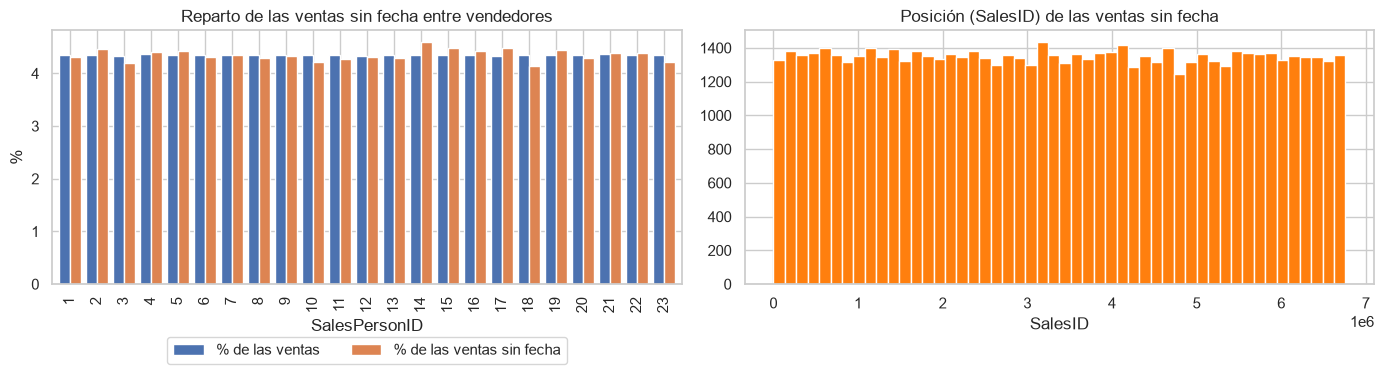

In [8]:
no_date = sales["SalesDate"].isna()
by_seller = pd.DataFrame(
    {
        "% de las ventas": 100 * sales["SalesPersonID"].value_counts(normalize=True),
        "% de las ventas sin fecha": 100
        * sales.loc[no_date, "SalesPersonID"].value_counts(normalize=True),
    }
).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_seller.plot.bar(ax=axes[0], width=0.8)
axes[0].set_title("Reparto de las ventas sin fecha entre vendedores")
axes[0].set_xlabel("SalesPersonID")
axes[0].set_ylabel("%")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
axes[1].hist(sales.loc[no_date, "SalesID"], bins=50, color="tab:orange")
axes[1].set_title("Posición (SalesID) de las ventas sin fecha")
axes[1].set_xlabel("SalesID")
fig.tight_layout()

chi2 = stats.chisquare(
    sales.loc[no_date, "SalesPersonID"].value_counts().sort_index(),
    sales["SalesPersonID"].value_counts(normalize=True).sort_index() * no_date.sum(),
)
print(f"Ventas sin fecha: {no_date.sum():,} ({100 * no_date.mean():.2f}%)")
print(f"Chi-cuadrado (¿se reparten igual que las ventas?): p = {chi2.pvalue:.3f}")

lost = (
    100
    * sales.loc[no_date, "SalesPersonID"].value_counts()
    / sales["SalesPersonID"].value_counts()
)
print(
    f"% de sus ventas que pierde cada vendedor: entre {lost.min():.2f}% y {lost.max():.2f}%"
)

Las ventas sin fecha (1%) aparecen a lo largo de toda la tabla, no en un periodo concreto. Con tantas filas, el chi-cuadrado detecta que el reparto entre vendedores **no es exactamente** proporcional (p = 0.009), pero la diferencia es pequeña: cada vendedor pierde entre ~0.95% y ~1.05% de sus ventas. Eso es mucho menor que la brecha de ~2% entre el mejor y el peor vendedor, así que **descartarlas no cambia la comparación**. Imputar una fecha inventada sería peor que descartarlas.

Ahora los duplicados, por fila completa y por identificador:

In [9]:
dups = pd.DataFrame(
    {
        "filas duplicadas": {n: int(df.duplicated().sum()) for n, df in raw.items()},
        "IDs duplicados": {
            n: int(df.iloc[:, 0].duplicated().sum()) for n, df in raw.items()
        },
    }
)
print(
    "TransactionNumber duplicados en sales:",
    sales["TransactionNumber"].duplicated().sum(),
)
dups

TransactionNumber duplicados en sales: 0


,filas duplicadas,IDs duplicados
sales,0,0
products,0,0
categories,0,0
employees,0,0
customers,0,0
cities,0,0
countries,0,0


No hay duplicados en ninguna tabla, y cada `TransactionNumber` es único: **cada fila de `sales` es una transacción distinta** (no hay canastas con varias líneas).

### `TotalPrice`: una columna que hay que recalcular

In [10]:
print(sales["TotalPrice"].describe())
print("\n% de filas con TotalPrice = 0:", 100 * (sales["TotalPrice"] == 0).mean())

count   6,758,125.00
mean            0.00
std             0.00
min             0.00
25%             0.00
50%             0.00
75%             0.00
max             0.00
Name: TotalPrice, dtype: float64

% de filas con TotalPrice = 0: 100.0


`TotalPrice` está en **0 en el 100% de las filas**, así que no sirve para medir ventas. Se recalcula con el precio del producto:

$$\text{Revenue} = \text{Price} \times \text{Quantity} \times (1 - \text{Discount})$$

In [11]:
products = raw["products"]
check = sales.head(5).merge(products[["ProductID", "Price"]], on="ProductID")
check["Revenue"] = check["Price"] * check["Quantity"] * (1 - check["Discount"])
check[
    ["SalesID", "ProductID", "Price", "Quantity", "Discount", "TotalPrice", "Revenue"]
]

,SalesID,ProductID,Price,Quantity,Discount,TotalPrice,Revenue
0,1,381,44.23,7,0.00,0.00,309.64
1,2,61,62.55,7,0.00,0.00,437.82
2,3,23,79.02,24,0.00,0.00,"1,896.44"
3,4,176,81.32,19,0.20,0.00,"1,236.01"
4,5,310,79.98,9,0.00,0.00,719.80


### Faltantes "escondidos" y lectura de códigos

In [12]:
default = pd.read_csv("data/01_raw/countries.csv")
print("Leído con las opciones por defecto de pandas:")
print(default[default["CountryCode"].isna()])
print("\nLeído con el catálogo (keep_default_na: false):")
print(raw["countries"][raw["countries"]["CountryName"] == "Australia"])

Leído con las opciones por defecto de pandas:
     CountryID CountryName CountryCode
145        146   Australia         NaN

Leído con el catálogo (keep_default_na: false):
     CountryID CountryName CountryCode
145        146   Australia          NA


In [13]:
for col in ["Class", "Resistant", "IsAllergic"]:
    print(products[col].value_counts().to_dict())
print(
    "VitalityDays = 0:",
    f"{100 * (products['VitalityDays'] == 0).mean():.0f}% de los productos",
)

{'Medium': 156, 'Low': 153, 'High': 143}
{'Durable': 164, 'Weak': 148, 'Unknown': 140}
{'False': 165, 'True': 157, 'Unknown': 130}
VitalityDays = 0: 61% de los productos


**Hallazgos de la sección 2**

| Problema | Decisión |
|---|---|
| `TotalPrice` = 0 en todas las filas | Se elimina y se recalcula `Revenue = Price × Quantity × (1 − Discount)` (`clean_sales` y `build_sales_primary`). |
| 67,526 ventas (1%) sin `SalesDate` | Se descartan (`clean_sales`). Cada vendedor pierde entre ~0.95% y ~1.05% de sus ventas, un efecto mucho menor que las diferencias entre vendedores. |
| `CountryCode` de Australia es `"NA"` | No es un faltante: el catálogo lo lee con `keep_default_na: false`. |
| `MiddleInitial` vacía en 977 clientes | Se ignora: no se usa en el análisis. |
| `Resistant` e `IsAllergic` con valor `"Unknown"`, y `VitalityDays` en 0 para el 61% de los productos | Son faltantes "escondidos", pero son atributos de producto que no se usan en el Reto 1. Se dejan como están. |
| Duplicados | No hay. De todas formas, el pipeline los elimina por `SalesID` y `TransactionNumber` si aparecen en datos futuros. |

## 3. Distribuciones y outliers

Para revisar las ventas se arma una tabla de trabajo: ventas con fecha, el precio del producto y el ingreso recalculado. Los outliers se buscan con la regla del **rango intercuartílico (IQR)**: un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR.

In [14]:
df = sales.dropna(subset=["SalesDate"]).merge(
    products[["ProductID", "Price"]], on="ProductID"
)
df["SalesDate"] = pd.to_datetime(df["SalesDate"])
df["Revenue"] = df["Price"] * df["Quantity"] * (1 - df["Discount"])


def iqr_outliers(x: pd.Series) -> dict:
    # cuenta valores fuera de [Q1 - 1.5 IQR, Q3 + 1.5 IQR]
    q1, q3 = x.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n = int(((x < low) | (x > high)).sum())
    return {
        "mín": x.min(),
        "máx": x.max(),
        "límite inferior": low,
        "límite superior": high,
        "outliers": n,
        "% outliers": 100 * n / len(x),
    }


pd.DataFrame(
    {
        "Quantity (por venta)": iqr_outliers(df["Quantity"]),
        "Price (por producto)": iqr_outliers(products["Price"]),
        "Revenue (por venta)": iqr_outliers(df["Revenue"]),
    }
).T

,mín,máx,límite inferior,límite superior,outliers,% outliers
Quantity (por venta),1.00,25.00,-11.00,37.00,0.00,0.00
Price (por producto),0.04,99.88,-46.98,148.98,0.00,0.00
Revenue (por venta),0.04,"2,496.89","-1,023.99","2,188.38","48,649.00",0.73


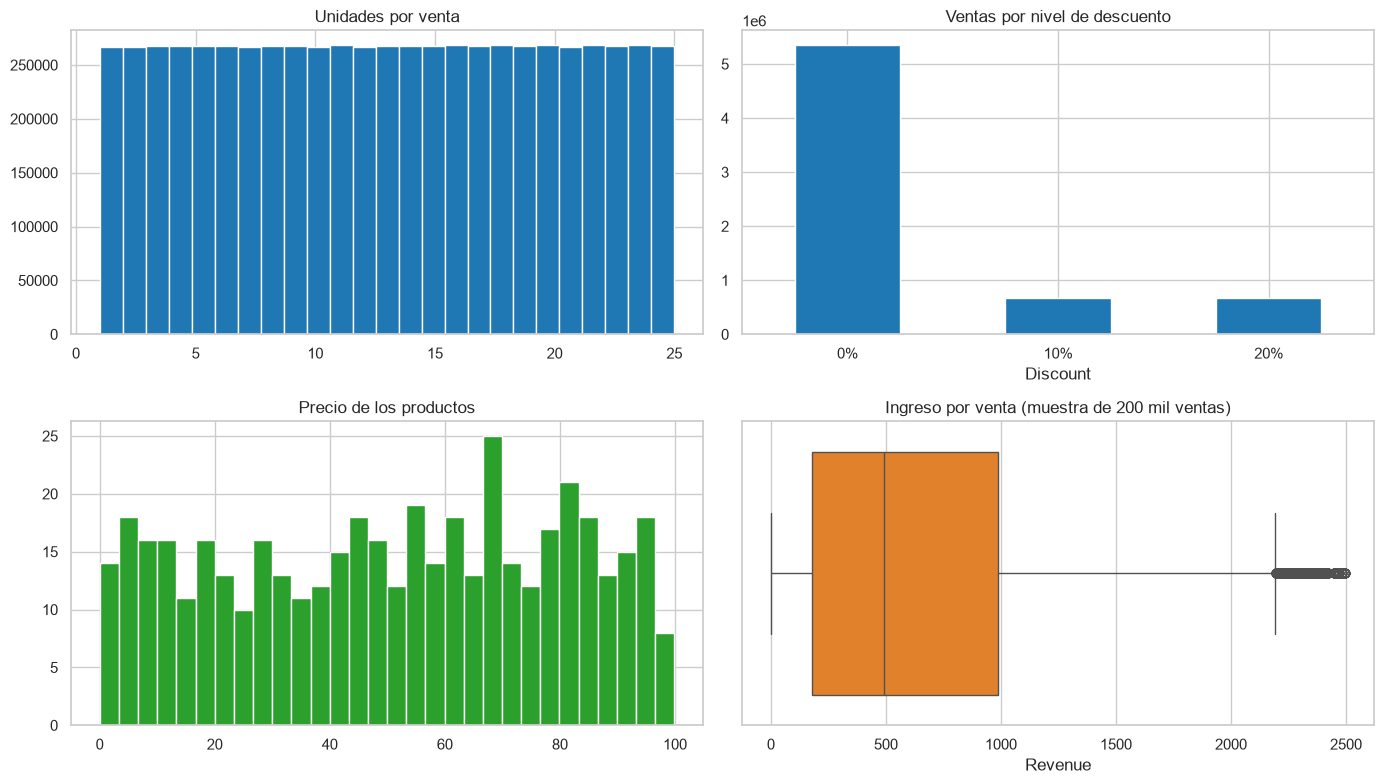

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].hist(df["Quantity"], bins=25, color="tab:blue")
axes[0, 0].set_title("Unidades por venta")
df["Discount"].value_counts().sort_index().rename(lambda d: f"{d:.0%}").plot.bar(
    ax=axes[0, 1], color="tab:blue", rot=0
)
axes[0, 1].set_title("Ventas por nivel de descuento")
axes[1, 0].hist(products["Price"], bins=30, color="tab:green")
axes[1, 0].set_title("Precio de los productos")
sns.boxplot(
    x=df["Revenue"].sample(200_000, random_state=0), ax=axes[1, 1], color="tab:orange"
)
axes[1, 1].set_title("Ingreso por venta (muestra de 200 mil ventas)")
fig.tight_layout()

- **Unidades por venta:** van de 1 a 25 con una distribución prácticamente **uniforme**. No hay outliers.
- **Descuento:** solo toma tres valores: 0% (80% de las ventas), 10% y 20%.
- **Precio:** entre 0.04 y 99.88, también casi uniforme. No hay outliers por IQR. Los precios más bajos se revisan abajo.
- **Ingreso por venta:** el IQR marca ~0.7% de las ventas como altas, pero el ingreso tiene un **tope natural** (precio máximo × 25 unidades ≈ 2,497). Esas ventas son combinaciones válidas de un producto caro con muchas unidades, no errores.

In [16]:
print("Productos más baratos:")
print(products.nsmallest(5, "Price")[["ProductName", "Price"]].to_string(index=False))
print("\nVentas con mayor ingreso:")
print(
    df.nlargest(3, "Revenue")[
        ["ProductID", "Price", "Quantity", "Discount", "Revenue"]
    ].to_string(index=False)
)
print(
    f"\nTope teórico: {products['Price'].max():.2f} × 25 = {products['Price'].max() * 25:,.2f}"
)

Productos más baratos:
                  ProductName  Price
Bread Crumbs - Japanese Style   0.04
            Apricots - Halves   0.37
Pastry - Raisin Muffin - Mini   0.43
   Sole - Dover, Whole, Fresh   0.68
         Bread Fig And Almond   1.19

Ventas con mayor ingreso:
 ProductID  Price  Quantity  Discount  Revenue
        98  99.88        25      0.00 2,496.89
        98  99.88        25      0.00 2,496.89
        98  99.88        25      0.00 2,496.89

Tope teórico: 99.88 × 25 = 2,496.89


### Venta diaria por vendedor

La unidad que se modela es la venta de cada vendedor por día, así que también se revisan outliers a ese nivel.

Vendedor-días: 2,967
Outliers por IQR: 12 (0.40%)
Vendedor-días con |z| > 3 respecto a su propio promedio: 4
Variación de la venta diaria (CV): 2.8%


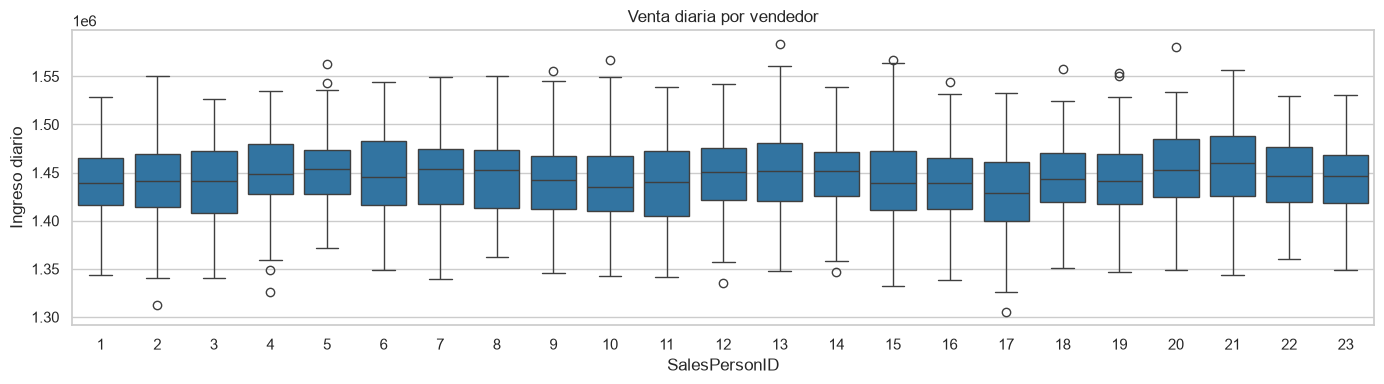

In [17]:
seller_day = (
    df.groupby(["SalesPersonID", df["SalesDate"].dt.normalize()])["Revenue"]
    .sum()
    .rename("Revenue")
)
z = seller_day.groupby(level=0).transform(lambda s: (s - s.mean()) / s.std())

fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(
    data=seller_day.reset_index(),
    x="SalesPersonID",
    y=seller_day.name,
    ax=ax,
    color="tab:blue",
)
ax.set_title("Venta diaria por vendedor")
ax.set_ylabel("Ingreso diario")
fig.tight_layout()

out = iqr_outliers(seller_day)
print(f"Vendedor-días: {len(seller_day):,}")
print(f"Outliers por IQR: {out['outliers']} ({out['% outliers']:.2f}%)")
print(f"Vendedor-días con |z| > 3 respecto a su propio promedio: {(z.abs() > 3).sum()}")
print(
    f"Variación de la venta diaria (CV): {100 * seller_day.std() / seller_day.mean():.1f}%"
)

### Perfil de los vendedores

,count,mean,std,min,25%,50%,75%,max
Age,23.00,50.45,11.42,28.70,44.27,53.91,55.96,66.84
TenureYears,23.00,4.73,2.18,1.24,2.97,4.88,6.46,8.21


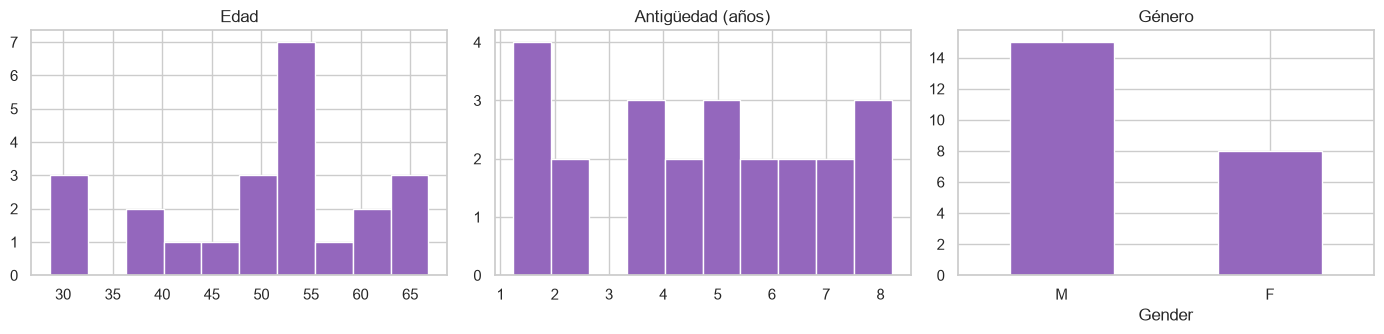

In [18]:
employees = raw["employees"].copy()
ref = pd.Timestamp("2018-05-10")
employees["Age"] = (ref - pd.to_datetime(employees["BirthDate"])).dt.days / 365.25
employees["TenureYears"] = (
    ref - pd.to_datetime(employees["HireDate"])
).dt.days / 365.25

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(employees["Age"], bins=10, color="tab:purple")
axes[0].set_title("Edad")
axes[1].hist(employees["TenureYears"], bins=10, color="tab:purple")
axes[1].set_title("Antigüedad (años)")
employees["Gender"].value_counts().plot.bar(ax=axes[2], color="tab:purple", rot=0)
axes[2].set_title("Género")
fig.tight_layout()
employees[["Age", "TenureYears"]].describe().T

**Hallazgos de la sección 3**

- **No se elimina ningún outlier.** Unidades, precios y descuentos están acotados y casi uniformes. Los valores que el IQR marca en el ingreso por venta y en la venta diaria son combinaciones válidas dentro de los límites del negocio, no errores de captura. Quitarlos borraría ventas reales.
- Algunos precios no son realistas (por ejemplo, un pescado entero a 0.68 o pan molido a 0.04), y unidades y precios siguen distribuciones casi uniformes. Junto con la homogeneidad entre vendedores, esto sugiere que el dataset es **simulado**. Se usan los precios tal como vienen, porque no hay una fuente para corregirlos, y se documenta como limitación.
- La venta diaria por vendedor es **muy estable** (~2.8% de variación). Solo 4 de 2,967 vendedor-días se alejan más de 3 desviaciones de su propio promedio.
- Los 23 vendedores tienen entre 29 y 67 años (mediana 54) y entre 1 y 8 años de antigüedad: 15 hombres y 8 mujeres. Con **23 personas**, cualquier conclusión sobre el perfil tendrá poca potencia estadística.
- **Decisión:** el pipeline valida rangos (`quantity_range` de 1 a 1000 y descuentos válidos de 0%, 10% y 20%) para detectar errores en datos futuros, en lugar de recortar por IQR. Edad y antigüedad se calculan a la fecha de corte del 10 de mayo de 2018 (`clean_employees`).

## 4. Patrones de venta, vendedores y señal para el modelo

### 4.1 Tendencia en el tiempo

,ingreso_total,dias,ingreso_por_dia
SalesDate,,,
2018-01,"1,030.74",31.00,33.25
2018-02,929.20,28.00,33.19
2018-03,"1,032.20",31.00,33.30
2018-04,997.27,30.00,33.24
2018-05,299.83,9.00,33.31


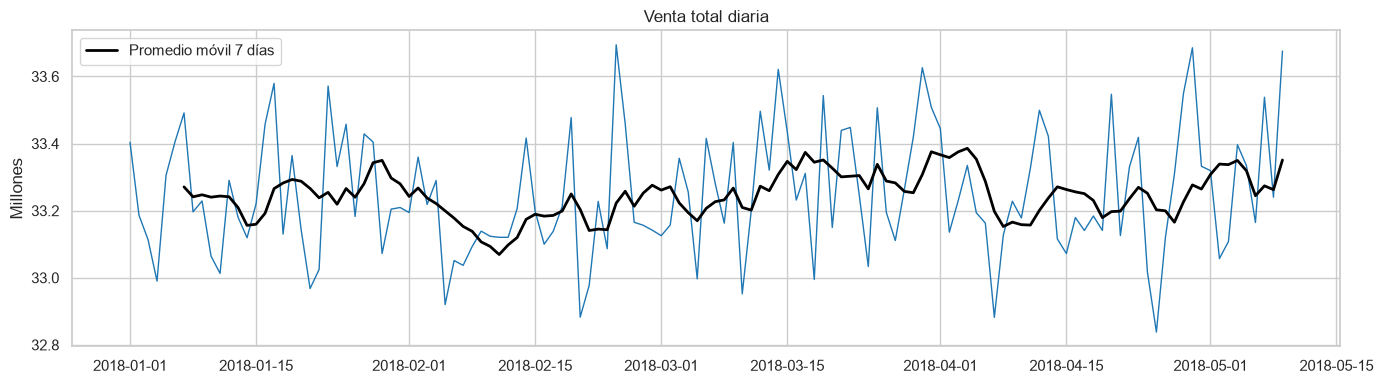

In [19]:
daily = df.groupby(df["SalesDate"].dt.normalize())["Revenue"].sum() / 1e6

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily.to_numpy(), color="tab:blue", lw=1)
ax.plot(
    daily.index,
    daily.rolling(7).mean().to_numpy(),
    color="black",
    lw=2,
    label="Promedio móvil 7 días",
)
ax.set_title("Venta total diaria")
ax.set_ylabel("Millones")
ax.legend()
fig.tight_layout()

monthly = df.groupby(df["SalesDate"].dt.to_period("M")).agg(
    ingreso_total=("Revenue", "sum"), dias=("SalesDate", lambda s: s.dt.date.nunique())
)
monthly["ingreso_por_dia"] = monthly["ingreso_total"] / monthly["dias"]
monthly / [1e6, 1, 1e6]

Si se mira el **total mensual**, mayo parece una caída fuerte, pero es un artefacto: mayo solo tiene 9 días. **Por día**, todos los meses venden prácticamente lo mismo (~Q33M). Por eso las tendencias se miden por día o por semana completa, nunca por mes.

### 4.2 Hora del día y día de la semana

ANOVA por día de la semana: p = 0.87


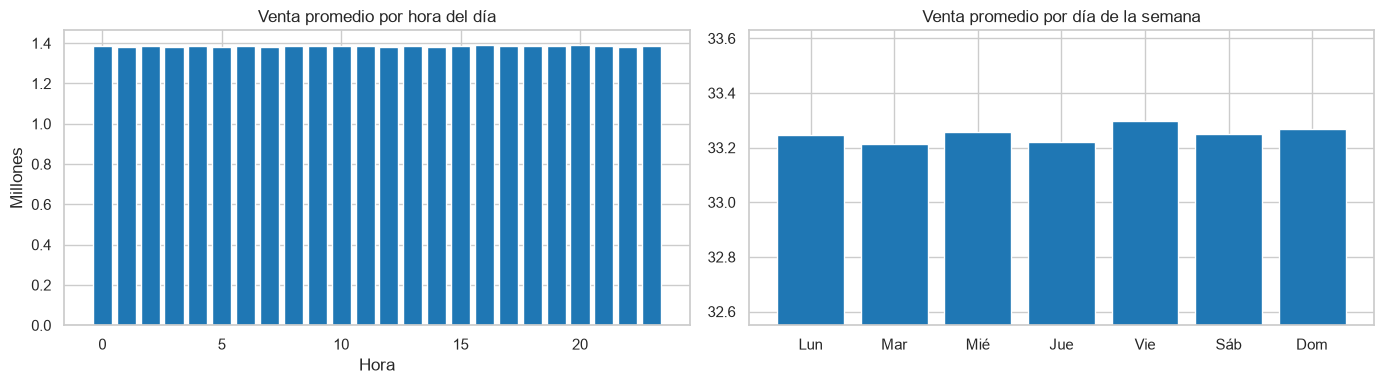

In [20]:
weekdays = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
by_hour = df.groupby(df["SalesDate"].dt.hour)["Revenue"].sum() / daily.size / 1e6
by_weekday = daily.groupby(daily.index.day_of_week).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_hour.index, by_hour.to_numpy(), color="tab:blue")
axes[0].set_title("Venta promedio por hora del día")
axes[0].set_xlabel("Hora")
axes[0].set_ylabel("Millones")
axes[1].bar(weekdays, by_weekday.to_numpy(), color="tab:blue")
axes[1].set_ylim(by_weekday.min() * 0.98, by_weekday.max() * 1.01)
axes[1].set_title("Venta promedio por día de la semana")
fig.tight_layout()

anova_weekday = stats.f_oneway(
    *[g.to_numpy() for _, g in daily.groupby(daily.index.day_of_week)]
)
print(f"ANOVA por día de la semana: p = {anova_weekday.pvalue:.2f}")

No hay horas pico ni días fuertes: la venta se reparte de forma pareja durante las 24 horas y los 7 días de la semana (ANOVA p = 0.87). No hay estacionalidad que aprovechar ni en el modelo ni en la asignación de turnos.

### 4.3 ¿En qué se diferencian los vendedores?

In [21]:
sd = (
    df.groupby(["SalesPersonID", df["SalesDate"].dt.normalize()])
    .agg(Revenue=("Revenue", "sum"), NumSales=("SalesID", "size"))
    .reset_index()
)
sd["AvgTicket"] = sd["Revenue"] / sd["NumSales"]


def anova_by_seller(data: pd.DataFrame, col: str) -> float:
    return stats.f_oneway(
        *[g[col].to_numpy() for _, g in data.groupby("SalesPersonID")]
    ).pvalue


pd.DataFrame(
    {
        "variable": [
            "Ingreso diario",
            "Número de ventas por día",
            "Ticket promedio por día",
            "Unidades por venta",
            "Precio del producto vendido",
        ],
        "nivel": ["vendedor-día"] * 3 + ["transacción"] * 2,
        "p-value ANOVA": [
            anova_by_seller(sd, "Revenue"),
            anova_by_seller(sd, "NumSales"),
            anova_by_seller(sd, "AvgTicket"),
            anova_by_seller(df, "Quantity"),
            anova_by_seller(df, "Price"),
        ],
    }
).style.format({"p-value ANOVA": "{:.1e}"})

,variable,nivel,p-value ANOVA
0,Ingreso diario,vendedor-día,1.8e-07
1,Número de ventas por día,vendedor-día,4.0e-01
2,Ticket promedio por día,vendedor-día,2.3e-18
3,Unidades por venta,transacción,2.2e-01
4,Precio del producto vendido,transacción,7.6e-01


Los vendedores **sí difieren en ingreso y en ticket promedio**, pero **no en el número de ventas**. Tampoco difieren, por separado, en las unidades que venden ni en el precio de los productos. Entonces, ¿de dónde sale la diferencia de ticket? De la **combinación**: en qué productos ponen las unidades.

Mejor ticket (vendedor 20): 13.16 unidades por venta premium
Peor ticket (vendedor 17): 12.81 unidades por venta premium


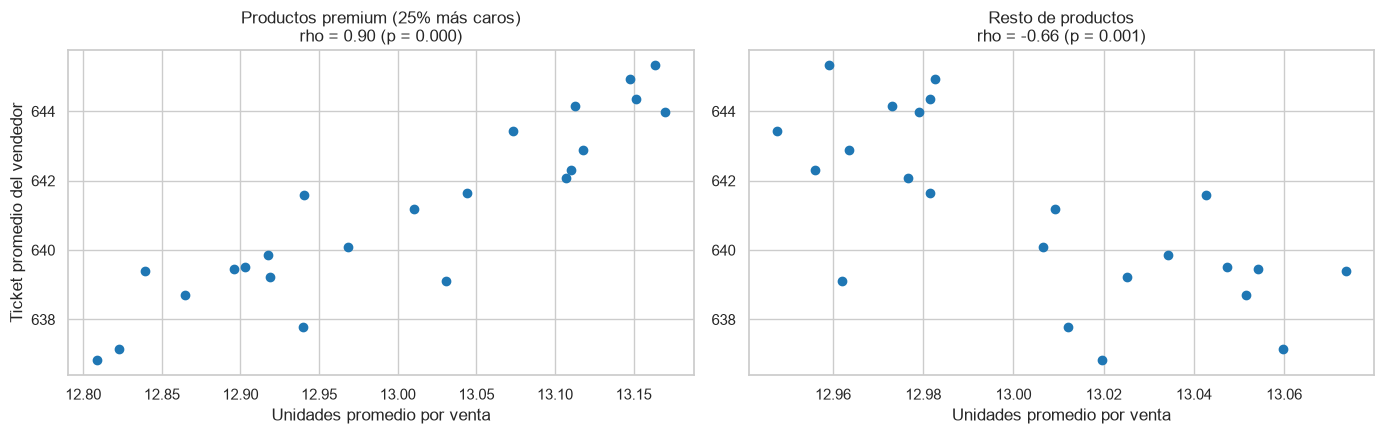

In [22]:
premium = df["Price"] > df["Price"].quantile(0.75)
mix = pd.DataFrame(
    {
        "ticket_promedio": df.groupby("SalesPersonID")["Revenue"].mean(),
        "unidades_en_premium": df[premium].groupby("SalesPersonID")["Quantity"].mean(),
        "unidades_en_resto": df[~premium].groupby("SalesPersonID")["Quantity"].mean(),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, title in [
    (axes[0], "unidades_en_premium", "Productos premium (25% más caros)"),
    (axes[1], "unidades_en_resto", "Resto de productos"),
]:
    rho, p = stats.spearmanr(mix[col], mix["ticket_promedio"])
    ax.scatter(mix[col], mix["ticket_promedio"], color="tab:blue")
    ax.set_title(f"{title}\nrho = {rho:.2f} (p = {p:.3f})")
    ax.set_xlabel("Unidades promedio por venta")
axes[0].set_ylabel("Ticket promedio del vendedor")
fig.tight_layout()

top, bottom = mix["ticket_promedio"].idxmax(), mix["ticket_promedio"].idxmin()
print(
    f"Mejor ticket (vendedor {top}): {mix.loc[top, 'unidades_en_premium']:.2f} unidades por venta premium"
)
print(
    f"Peor ticket (vendedor {bottom}): {mix.loc[bottom, 'unidades_en_premium']:.2f} unidades por venta premium"
)

El patrón es claro:

- Los vendedores con mejor ticket venden **más unidades por venta en los productos premium** (rho = 0.90) y **menos en los baratos** (rho = −0.66).
- En total venden las mismas unidades que los demás, pero las **concentran en lo caro**. Por ejemplo, el mejor ticket vende 13.16 unidades por venta premium y el peor 12.81.

La diferencia es pequeña (el ticket varía ~1.3% entre extremos), pero es el único comportamiento que separa a los vendedores. Es una habilidad entrenable: **impulsar más unidades en los productos de mayor precio**.

In [23]:
categories = df.merge(products[["ProductID", "CategoryID"]], on="ProductID")
chi_cat = stats.chi2_contingency(
    pd.crosstab(categories["SalesPersonID"], categories["CategoryID"])
)
chi_prod = stats.chi2_contingency(pd.crosstab(df["SalesPersonID"], df["ProductID"]))
print(f"¿Venden distintas categorías? chi-cuadrado p = {chi_cat.pvalue:.2f}")
print(f"¿Venden distintos productos?  chi-cuadrado p = {chi_prod.pvalue:.2f}")

¿Venden distintas categorías? chi-cuadrado p = 0.27
¿Venden distintos productos?  chi-cuadrado p = 0.38


### 4.4 Descuentos

In [24]:
disc = df.groupby("Discount").agg(
    ventas=("SalesID", "size"),
    unidades_por_venta=("Quantity", "mean"),
    ingreso_por_venta=("Revenue", "mean"),
)
disc["% de las ventas"] = 100 * disc["ventas"] / disc["ventas"].sum()
discount_given = (df["Price"] * df["Quantity"] * df["Discount"]).sum()
anova_disc = stats.f_oneway(
    *[g["Quantity"].to_numpy() for _, g in df.groupby("Discount")]
)
print(f"Descuento otorgado en el periodo: Q{discount_given / 1e6:,.1f} millones")
print(f"ANOVA unidades por nivel de descuento: p = {anova_disc.pvalue:.2f}")
disc

Descuento otorgado en el periodo: Q132.5 millones
ANOVA unidades por nivel de descuento: p = 0.06


,ventas,unidades_por_venta,ingreso_por_venta,% de las ventas
Discount,,,,
0.00,5353035,13.00,660.88,80.01
0.10,670318,13.02,595.21,10.02
0.20,667246,13.00,528.36,9.97


Con o sin descuento se venden **las mismas ~13 unidades por venta**, y la diferencia no es significativa. El descuento no genera volumen adicional: solo reduce el ingreso de esa venta.

### 4.5 Señal para el modelo: ¿la venta de hoy se parece a la de días anteriores?

Para pronosticar la venta diaria de un vendedor, lo natural es usar su historial (ayer, hace una semana, su promedio). La **autocorrelación** mide cuánto se parece la venta de hoy a la de *k* días antes.

Autocorrelación máxima (en valor absoluto): 0.044
Variación de la venta diaria alrededor del promedio de cada vendedor: 2.8%


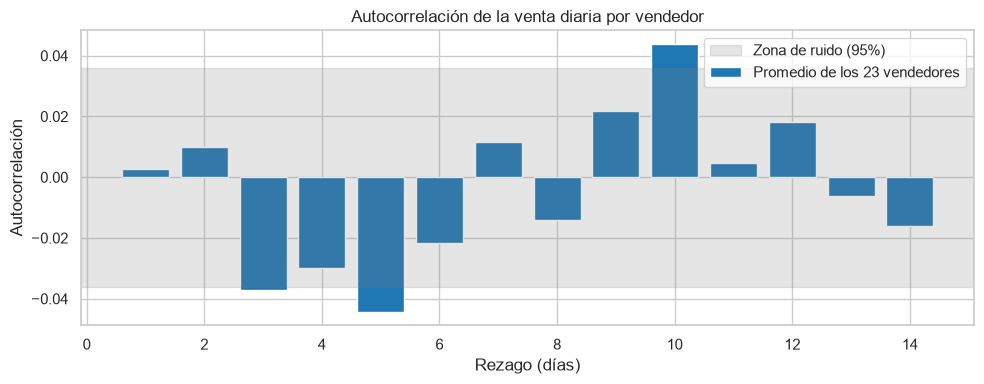

In [25]:
import numpy as np

lags = range(1, 15)
acf = pd.DataFrame(
    {
        seller: [g.set_index("SalesDate")["Revenue"].autocorr(lag) for lag in lags]
        for seller, g in sd.groupby("SalesPersonID")
    },
    index=lags,
)
# zona de ruido para el promedio de 23 series de 129 días
band = 1.96 / np.sqrt(sd["SalesDate"].nunique() * sd["SalesPersonID"].nunique())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(
    acf.index, acf.mean(axis=1), color="tab:blue", label="Promedio de los 23 vendedores"
)
ax.axhspan(-band, band, color="grey", alpha=0.2, label="Zona de ruido (95%)")
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")
ax.set_title("Autocorrelación de la venta diaria por vendedor")
ax.legend()
fig.tight_layout()

seller_mean = sd.groupby("SalesPersonID")["Revenue"].transform("mean")
print(f"Autocorrelación máxima (en valor absoluto): {acf.mean(axis=1).abs().max():.3f}")
print(
    f"Variación de la venta diaria alrededor del promedio de cada vendedor: {100 * (sd['Revenue'] / seller_mean - 1).std():.1f}%"
)

Todas las autocorrelaciones son mínimas (|r| ≤ 0.05). Algunos rezagos rozan el borde de la zona de ruido, pero una correlación de 0.05 explica menos del 0.3% de la variación: **la venta de ayer o de la semana pasada prácticamente no ayuda a anticipar la de hoy**. Lo que sí es estable es el **nivel** de cada vendedor (su promedio), y los días oscilan ±2.8% alrededor de él.

Esto anticipa el resultado del modelo: un pronóstico basado en el **promedio histórico de cada vendedor** será difícil de superar. Por eso el pipeline compara los modelos de ML contra esa línea base, y solo adopta uno si la mejora lo justifica.